# Systemy AI – Laboratorium 1
## Python, NumPy i pierwsze metryki klasyfikacji

**Cel:** przypomnienie Pythona w kontekście pracy z wynikami modeli, samodzielna implementacja metryk klasyfikacji binarnej i pierwszy mały eksperyment z hipotezą.

**Zasady**
- Zapisz kopię notatnika na swoim Dysku: *Plik → Zapisz kopię na Dysku*, nazwa `Lab1_AI_Nazwisko.ipynb`.
- Rozwiązania wpisuj w komórkach `# Twoje rozwiązanie`, odpowiedzi opisowe w komórkach *Twoja odpowiedź*.
- Komórki oznaczone `# TEST` sprawdzają rozwiązanie. Nie zmieniaj ich; jeśli zgłaszają błąd, popraw kod powyżej.
- Przed oddaniem: *Środowisko wykonawcze → Uruchom ponownie i uruchom wszystko*. Notatnik musi wykonać się od góry do dołu bez błędów.



**Materiały pomocnicze**
- Python: https://www.w3schools.com/python/ oraz https://www.kaggle.com/learn/python
- NumPy: https://numpy.org/doc/stable/user/quickstart.html
- Metryki w scikit-learn: https://scikit-learn.org/stable/modules/model_evaluation.html

---
## Część A. Rozgrzewka

### Zadanie A1. Pierwsze komórki
1. Wypisz instrukcją `print` tekst `Hello, Artificial Intelligence!`.

In [269]:
# Twoje rozwiązanie
print("Hello, Artificial Intelligence!")

Hello, Artificial Intelligence!


*Twoja odpowiedź:* Wypisano

### Zadanie A2. Zmienne i typy
Zadeklaruj zmienne `model`, `version`, `accuracy`, `deployed` o wartościach `"NeuralNet"`, `2`, `0.94`, `True`.

1. Wypisz typ każdej zmiennej (`type()`).
2. Zbuduj i wypisz zdanie `Model NeuralNet (v2) osiąga dokładność 0.94.` na dwa sposoby: przez konkatenację (`+`, zmienna `s1`) oraz jako f-string (zmienna `s2`).


In [270]:
# Twoje rozwiązanie
model = "NeuralNet"
version = 2
accuracy = 0.94
deployed = True

print(type(model))
print(type(version))
print(type(accuracy))
print(type(deployed))

s1 = "Model " + model + " (v" + str(version) + ") osiąga dokładność " + str(accuracy) + "."
s2 = f"Model {model} (v{version}) osiąga dokładność {accuracy}."

print(s1)
print(s2)

<class 'str'>
<class 'int'>
<class 'float'>
<class 'bool'>
Model NeuralNet (v2) osiąga dokładność 0.94.
Model NeuralNet (v2) osiąga dokładność 0.94.


In [271]:
# TEST
assert s1 == s2 == "Model NeuralNet (v2) osiąga dokładność 0.94."
print("A2 OK")

A2 OK


### Zadanie A3. Średnia i odchylenie standardowe
Dla listy `acc = [0.78, 0.86, 0.92, 0.81]` oblicz **bez bibliotek**:
- średnią `mean_acc`,
- odchylenie standardowe populacji `std_acc` (z dzieleniem przez $n$):

$$\sigma = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_i-\bar{x})^2}$$

W komórce tekstowej zinterpretuj wynik: co mówi odchylenie o tych czterech modelach? Jak zmieni się wartość, jeśli podzielisz przez $n-1$, i kiedy stosuje się ten wariant?

In [272]:
# Twoje rozwiązanie
acc = [0.78, 0.86, 0.92, 0.81]
mean_acc = sum(acc) / len(acc)
std_acc = (sum((x - mean_acc) ** 2 for x in acc) / len(acc)) ** 0.5

print(mean_acc)
print(std_acc)

std_acc_n = (sum((x - mean_acc) ** 2 for x in acc) / (len(acc) - 1)) ** 0.5
print(std_acc_n)

0.8425
0.05309190145398825
0.0613052471924984


In [273]:
# TEST
assert abs(mean_acc - 0.8425) < 1e-9
assert abs(std_acc - 0.05309) < 1e-4, "Sprawdź, czy dzielisz przez n, a nie n-1"
print("A3 OK")

A3 OK


*Twoja odpowiedź:*

Niska wartość odchylenia oznacza, że wartości accuracy wszystkich czterech modeli są zbliżone do siebie.

Wartość odchylenia w przypadku dzielenia przez $$n-1$$ zmienia się w jakimś stopniu. Ten wariant stosuje się w przypadku badania jakiejś części ze wszystkich możliwych przypadków.

### Zadanie A4. Tekst i słownik częstości
Dla tekstu

`text = "AI systems learn from data. AI systems make predictions from data"`

1. Usuń interpunkcję, zamień litery na małe i podziel tekst na słowa.
2. Zbuduj słownik `counts` w postaci `{słowo: liczba_wystąpień}`.
3. Zapisz w liście `most_common` **wszystkie** słowa o największej liczbie wystąpień (uwaga na remisy) i wypisz ją.

In [274]:
# Twoje rozwiązanie
text = "AI systems learn from data. AI systems make predictions from data"
text = text.lower().replace(".", "").split()
counts = {}
for word in text:
    if word in counts:
        counts[word] += 1
    else:
        counts[word] = 1

most_common = [word for word, count in counts.items() if count == max(counts.values())]
print(most_common)

['ai', 'systems', 'from', 'data']


In [275]:
# TEST
assert counts["data"] == 2 and counts["learn"] == 1
assert sorted(most_common) == ["ai", "data", "from", "systems"]
print("A4 OK")

A4 OK


### Zadanie A5. Funkcja z walidacją
Napisz funkcję `performance_label(score)`, która zamienia wynik modelu `score` ∈ [0, 1] na etykietę:

| Warunek | Etykieta |
|---|---|
| `score < 0.75` | `"weak"` |
| `0.75 ≤ score ≤ 0.90` | `"average"` |
| `score > 0.90` | `"strong"` |

Wymagania:
- progi 0.75 i 0.90 należą do `"average"`; funkcja nie zaokrągla wejścia,
- dla wartości nieliczbowej (np. `"0.8"`, `None`) funkcja zgłasza `TypeError`,
- dla liczby spoza [0, 1] funkcja zgłasza `ValueError`.

Następnie dla listy `scores = [0.72, 0.81, 0.93, 0.88]` wypisz każdy wynik z etykietą i policz średnią `mean_ok` tylko z wyników, które **nie** są `"weak"`.

In [276]:
# Twoje rozwiązanie
def performance_label(score):
    if not isinstance(score, (int, float)):
        raise TypeError
    if score < 0 or score > 1:
        raise ValueError

    if score < 0.75:
        return "weak"
    elif score <= 0.90:
        return "average"
    else:
        return "strong"

scores = [0.72, 0.81, 0.93, 0.88]
suma = sum(score for score in scores if performance_label(score) != "weak")
mean_ok = suma/3
print(mean_ok)

0.8733333333333334


In [277]:
# TEST
assert [performance_label(s) for s in (0.74, 0.75, 0.90, 0.95)] == ["weak", "average", "average", "strong"]
assert performance_label(0) == "weak" and performance_label(1) == "strong"

for bad, exc in [(1.2, ValueError), (-0.1, ValueError), ("0.8", TypeError), (None, TypeError)]:
    try:
        performance_label(bad)
    except exc:
        pass
    else:
        raise AssertionError(f"Dla {bad!r} oczekiwano wyjątku {exc.__name__}")

assert abs(mean_ok - 0.87333) < 1e-4
print("A5 OK")

A5 OK


---
## Część B. Struktury danych i wyniki modeli

### Zadanie B1. Słownik wyników i ranking
1. Utwórz słownik `results`: `"SVM"` → 0.81, `"DecisionTree"` → 0.74, `"NeuralNet"` → 0.92.
2. Dodaj do niego `"Transformer"` → 0.95.
3. Oblicz średnią dokładność `mean_results` i utwórz listę `above_mean` z nazwami modeli o dokładności powyżej średniej.
4. Napisz funkcję `print_ranking(results)`, która drukuje ranking malejąco w formacie

```
1. Transformer – 0.95
2. NeuralNet – 0.92
...
Najlepszy model: Transformer – rekomendowany do wdrożenia
```

i **zwraca** nazwę najlepszego modelu. Funkcja nie może modyfikować przekazanego słownika.

In [278]:
# Twoje rozwiązanie
results = {"SVM": 0.81, "DecisionTree": 0.74, "NeuralNet": 0.92}
results["Transformer"] = 0.95
mean_results = sum(results.values()) / len(results)
above_mean = [model for model, score in results.items() if score > mean_results]

def print_ranking(results):
    best_model = max(results, key=results.get)
    for i, (model, score) in enumerate(sorted(results.items(), key=lambda x: x[1], reverse=True), start=1):
        print(f"{i}. {model} – {score}")
    print(f"Najlepszy model: {best_model} – rekomendowany do wdrożenia")
    return best_model

print_ranking(results)

1. Transformer – 0.95
2. NeuralNet – 0.92
3. SVM – 0.81
4. DecisionTree – 0.74
Najlepszy model: Transformer – rekomendowany do wdrożenia


'Transformer'

In [279]:
# TEST
assert abs(mean_results - 0.855) < 1e-9
assert sorted(above_mean) == ["NeuralNet", "Transformer"]
assert print_ranking({"A": 0.5, "B": 0.7}) == "B"
assert list(results) == ["SVM", "DecisionTree", "NeuralNet", "Transformer"], "Funkcja zmieniła słownik"
print("B1 OK")

1. B – 0.7
2. A – 0.5
Najlepszy model: B – rekomendowany do wdrożenia
B1 OK


### Zadanie B2. Filtrowanie błędnych wyników
Dane z eksperymentów bywają zanieczyszczone. Dla listy

`raw = [0.83, 0.92, 1.05, -0.12, 0.78, None]`

napisz funkcję `clean_scores(raw)`, która zwraca parę `(valid, n_invalid)`:
- `valid` – lista poprawnych wyników (liczby z zakresu [0, 1]),
- `n_invalid` – liczba odrzuconych wartości.

Wypisz komunikat dokładnie w formacie:

`Poprawne: 3 | Błędne: 3 | Średnia (poprawnych): 0.84`

*Dla dociekliwych:* co Twoja funkcja zrobi z wartościami `"0.9"` i `True`? Czy tak powinno być?

In [280]:
# Twoje rozwiązanie
def clean_scores(raw):
    valid = [score for score in raw if isinstance(score, (int, float)) and not isinstance(score, bool) and 0 <= score <= 1]
    n_invalid = len(raw) - len(valid)
    print(f"Poprawne: {len(valid)} | Błędne: {n_invalid} | Średnia (poprawnych): {sum(valid) / len(valid) if len(valid) > 0 else 0}")
    return valid, n_invalid

In [281]:
# TEST
assert clean_scores([0.83, 0.92, 1.05, -0.12, 0.78, None]) == ([0.83, 0.92, 0.78], 3)
assert clean_scores([0, 1, "0.9"]) == ([0, 1], 1)
print("B2 OK")

Poprawne: 3 | Błędne: 3 | Średnia (poprawnych): 0.8433333333333334
Poprawne: 2 | Błędne: 1 | Średnia (poprawnych): 0.5
B2 OK


Przy "0.9" i True, funkcja odrzuci element, przez co przy liczeniu n_invalid pokaże się liczba przypadków, gdzie element nie spełniał któregoś z warunków.

### Zadanie B3. Struktura zagnieżdżona
Dla struktury `model_info` (komórka niżej) napisz funkcję `summarize_model(info)`, która:
1. wypisuje nazwę modelu,
2. oblicza i wypisuje średnią ze **wszystkich** metryk w `info["metrics"]` (nie zakładaj, że są dokładnie trzy),
3. wypisuje `Model gotowy do wdrożenia`, jeśli średnia ≥ 0.9, w przeciwnym razie `Model wymaga poprawy`,
4. zapisuje średnią pod kluczem `info["mean_score"]` i zwraca cały słownik.

Wywołaj funkcję: `model_info = summarize_model(model_info)`.

In [282]:
model_info = {
    "name": "NeuralNet",
    "version": "1.2",
    "metrics": {"accuracy": 0.91, "precision": 0.88, "recall": 0.85},
    "status": "trained",
}

In [283]:
# Twoje rozwiązanie
def summarize_model(info):
    print(info["name"])
    mean_score = sum(info["metrics"].values()) / len(info["metrics"])
    print(mean_score)
    if mean_score >= 0.9:
        print("Model gotowy do wdrożenia")
    else:
        print("Model wymaga poprawy")
    info["mean_score"] = mean_score
    return info

model_info = summarize_model(model_info)

NeuralNet
0.88
Model wymaga poprawy


In [284]:
# TEST
assert abs(model_info["mean_score"] - 0.88) < 1e-9
assert abs(summarize_model({"name": "X", "metrics": {"accuracy": 0.95, "f1": 0.93}})["mean_score"] - 0.94) < 1e-9
print("B3 OK")

X
0.94
Model gotowy do wdrożenia
B3 OK


---
## Część C. Metryki klasyfikacji binarnej

Przypomnienie (klasa pozytywna = 1):

| | predykcja 1 | predykcja 0 |
|---|---|---|
| **prawda 1** | TP | FN |
| **prawda 0** | FP | TN |

$$\text{accuracy}=\frac{TP+TN}{TP+TN+FP+FN}\qquad \text{precision}=\frac{TP}{TP+FP}\qquad \text{recall}=\frac{TP}{TP+FN}\qquad F_1=\frac{2\cdot\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$$

In [285]:
y_true = [1, 0, 1, 1, 0, 0, 1, 0, 1, 0]
y_pred = [1, 0, 1, 0, 0, 1, 1, 0, 0, 0]

### Zadanie C1. Ręcznie, w czystym Pythonie
Używając pętli (bez bibliotek) policz i zapisz w zmiennych `TP`, `FP`, `FN`, `TN`, a następnie `precision`, `recall` i `f1`. Wypisz raport:

`TP=.. FP=.. FN=.. TN=.. / precision=.. recall=.. F1=..`

In [286]:
# Twoje rozwiązanie
TP = 0
TN = 0
FP = 0
FN = 0


for i, j in zip(y_true, y_pred):
    if i == 1 and j == 1:
        TP += 1
    elif i == 0 and j == 0:
        TN += 1
    elif i == 0 and j == 1:
        FP += 1
    elif i == 1 and j == 0:
        FN += 1

precision = TP/(TP + FP)
recall = TP/(TP + FN)
F1 = (2 * precision * recall)/(precision + recall)

print(f"TP={TP} FP={FP} FN={FN} TN={TN} / precision={precision} recall={recall} F1={F1}")

TP=3 FP=1 FN=2 TN=4 / precision=0.75 recall=0.6 F1=0.6666666666666665


In [287]:
# TEST
assert (TP, FP, FN, TN) == (3, 1, 2, 4)
assert abs(precision - 0.75) < 1e-9 and abs(recall - 0.6) < 1e-9 and abs(F1 - 2 / 3) < 1e-9
print("C1 OK")

C1 OK


### Zadanie C2. To samo w NumPy
Napisz funkcję `binary_metrics(y_true, y_pred)`, która **bez pętli** (maski logiczne i `sum`) zwraca słownik z kluczami

`"TP", "FP", "FN", "TN", "accuracy", "precision", "recall", "f1"`.

Jeśli mianownik którejś metryki jest równy 0 (np. model ani razu nie przewidział klasy 1), przyjmij dla niej wartość `0.0`. Funkcja ma działać zarówno dla list, jak i tablic NumPy.

In [288]:
import numpy as np

def binary_metrics(y_true, y_pred):
  y_true = np.asarray(y_true)
  y_pred = np.asarray(y_pred)

  TP = np.sum((y_true == 1) & (y_pred == 1))
  TN = np.sum((y_true == 0) & (y_pred == 0))
  FP = np.sum((y_true == 0) & (y_pred == 1))
  FN = np.sum((y_true == 1) & (y_pred == 0))
  accuracy = (TP + TN) / (TP + TN + FP + FN) if (TP + TN + FP + FN) != 0 else 0.0
  precision = TP / (TP + FP) if (TP + FP) != 0 else 0.0
  recall = TP / (TP + FN) if (TP + FN) != 0 else 0.0
  f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) != 0 else 0.0

  return {"TP": TP, "TN": TN, "FP": FP,"FN": FN, "accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}

In [289]:
# TEST
m = binary_metrics(y_true, y_pred)
assert (m["TP"], m["FP"], m["FN"], m["TN"]) == (3, 1, 2, 4)
assert abs(m["accuracy"] - 0.7) < 1e-9 and abs(m["f1"] - 2 / 3) < 1e-9

m0 = binary_metrics([1, 0, 0, 0], [0, 0, 0, 0])   # model nigdy nie przewiduje 1
assert m0["precision"] == 0.0 and m0["recall"] == 0.0 and m0["f1"] == 0.0
print("C2 OK")

C2 OK


### Zadanie C3. Porównanie ze scikit-learn
Policz te same wielkości funkcjami `confusion_matrix`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score` z modułu `sklearn.metrics` i sprawdź (`np.isclose`), że zgadzają się z wynikiem `binary_metrics`.

W komentarzu zapisz, w jakim układzie `confusion_matrix` zwraca TP, FP, FN, TN. Sprawdź to w dokumentacji, nie zgaduj.

In [290]:
# Twoje rozwiązanie
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

cmat = confusion_matrix(y_true, y_pred)
acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred)
rec = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print(cmat)
print(acc)
print(prec)
print(rec)
print(f1)

ccmat1 = np.isclose(cmat[1, 1], m["TP"])
print(f"TP: {ccmat1}")
ccmat2 = np.isclose(cmat[0, 1], m["FP"])
print(f"FP: {ccmat2}")
ccmat3 = np.isclose(cmat[1, 0], m["FN"])
print(f"FN: {ccmat3}")
ccmat4 = np.isclose(cmat[0, 0], m["TN"])
print(f"TN: {ccmat4}")
cacc = np.isclose(acc, m["accuracy"])
print(f"accuracy: {cacc}")
cprec = np.isclose(prec, m["precision"])
print(f"precision: {cprec}")
crec = np.isclose(rec, m["recall"])
print(f"recall: {crec}")
cf1 = np.isclose(f1, m["f1"])
print(f"f1: {cf1}")


#confusion_matrix zwraca macierz w układzie
#TN FP
#FN TP

#tzn.
#TN jest w pozycji {0,0}
#FP jest w pozycji {1,0}
#FN jest w pozycji {0,1}
#TP jest w pozycji {1,1}

[[4 1]
 [2 3]]
0.7
0.75
0.6
0.6666666666666666
TP: True
FP: True
FN: True
TN: True
accuracy: True
precision: True
recall: True
f1: True


---
## Część D. Mini-eksperyment: kiedy accuracy wprowadza w błąd

Rozważ dwa „modele” wykrywające rzadkie zjawisko (np. chorobę, awarię, oszustwo):

- **zawsze-zero** – niezależnie od wejścia odpowiada 0,
- **zaszumiony** – zna prawdziwą odpowiedź, ale w 10% przypadków (losowo) podaje przeciwną.

Parametr $p$ to udział klasy pozytywnej w danych.

### Zadanie D1. Hipoteza
**Zanim uruchomisz jakikolwiek kod**, zapisz przewidywania dla $p = 0.05$:
- jaką accuracy osiągnie każdy z modeli?
- który model będzie miał wyższą accuracy?
- jaką precision będzie miał model zaszumiony: bliżej 0.9, 0.5 czy 0.3?

*Twoja odpowiedź:*


1.   Accuracy osiągnie w:
*   zawsze-zero: 95%
*   zaszumiony: 90%

2.   Model zawsze-zero będzie miał wyższą accuracy

3.   zaszumiony model będzie mieć precyzję bliżej 0,3





Funkcja poniżej generuje dane. Jest gotowa, przeczytaj ją i upewnij się, że rozumiesz każdą linię.

In [291]:
import numpy as np

def make_data(p, n=10_000, error_rate=0.10, seed=42):
    """Zwraca (y_true, y_zero, y_noisy) dla udziału klasy pozytywnej p."""
    rng = np.random.default_rng(seed)
    y_true = (rng.random(n) < p).astype(int)        # 1 z prawdopodobieństwem p
    y_zero = np.zeros(n, dtype=int)                 # model zawsze-zero
    flip = rng.random(n) < error_rate               # które odpowiedzi odwrócić
    y_noisy = np.where(flip, 1 - y_true, y_true)    # model zaszumiony
    return y_true, y_zero, y_noisy

### Zadanie D2. Eksperyment
1. Dla $p = 0.05$ policz funkcją `binary_metrics` metryki obu modeli i porównaj z przewidywaniami z D1.
2. Powtórz obliczenia dla `ps = [0.5, 0.3, 0.1, 0.05, 0.01]`. Wyniki zbierz w tabeli `pandas.DataFrame` o nazwie `df` z kolumnami `p`, `model`, `accuracy`, `precision`, `recall`, `f1` (po jednym wierszu na parę: wartość $p$, model).
3. Narysuj wykres (matplotlib): oś X to $p$ w skali logarytmicznej, na osi Y accuracy obu modeli oraz precision modelu zaszumionego. Podpisz osie i dodaj legendę.

In [292]:
# Twoje rozwiązanie
import pandas as pd

y_true, y_zero, y_noisy = make_data(0.05)
m_zero = binary_metrics(y_true, y_zero)
m_noisy = binary_metrics(y_true, y_noisy)

print("Model zawsze-zero (p=0.05):")
for k, v in m_zero.items():
    print(f"  {k}: {v}")

print("\nModel zaszumiony (p=0.05):")
for k, v in m_noisy.items():
    print(f"  {k}: {v}")




Model zawsze-zero (p=0.05):
  TP: 0
  TN: 9492
  FP: 0
  FN: 508
  accuracy: 0.9492
  precision: 0.0
  recall: 0.0
  f1: 0.0

Model zaszumiony (p=0.05):
  TP: 470
  TN: 8566
  FP: 926
  FN: 38
  accuracy: 0.9036
  precision: 0.336676217765043
  recall: 0.9251968503937008
  f1: 0.49369747899159666


In [293]:
ps = [0.5, 0.3, 0.1, 0.05, 0.01]
rows = []

for p in ps:
    y_true, y_zero, y_noisy = make_data(p)
    m_zero = binary_metrics(y_true, y_zero)
    m_noisy = binary_metrics(y_true, y_noisy)

    rows.append({
        "p": p,
        "model": "zawsze-zero",
        "accuracy": m_zero["accuracy"],
        "precision": m_zero["precision"],
        "recall": m_zero["recall"],
        "f1": m_zero["f1"]
    })

    rows.append({
        "p": p,
        "model": "zaszumiony",
        "accuracy": m_noisy["accuracy"],
        "precision": m_noisy["precision"],
        "recall": m_noisy["recall"],
        "f1": m_noisy["f1"]
    })

df = pd.DataFrame(rows, columns=["p", "model", "accuracy", "precision", "recall", "f1"])

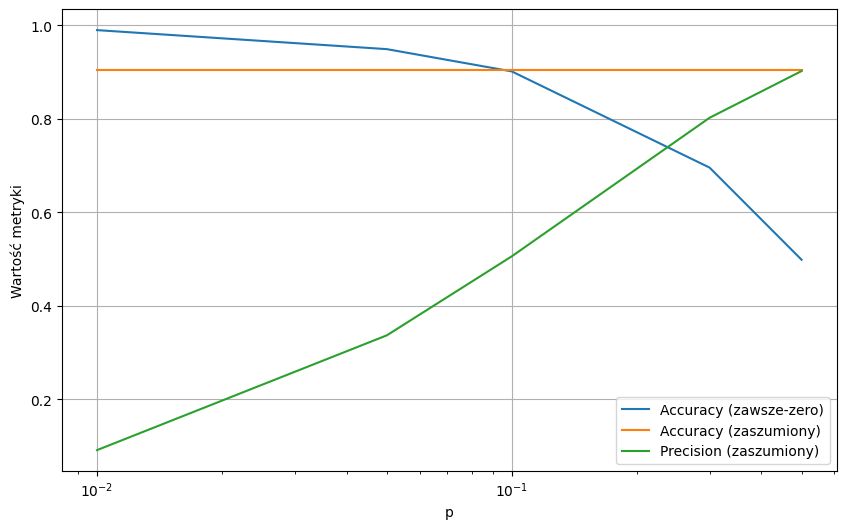

In [294]:
import matplotlib.pyplot as plt

df_zero = df[df["model"] == "zawsze-zero"].sort_values("p")
df_noisy = df[df["model"] == "zaszumiony"].sort_values("p")

plt.figure(figsize=(10, 6))

plt.plot(df_zero["p"], df_zero["accuracy"], label="Accuracy (zawsze-zero)")
plt.plot(df_noisy["p"], df_noisy["accuracy"], label="Accuracy (zaszumiony)")
plt.plot(df_noisy["p"], df_noisy["precision"], label="Precision (zaszumiony)")

plt.xscale("log")

plt.xlabel("p")
plt.ylabel("Wartość metryki")
plt.legend()
plt.grid()
plt.show()

In [295]:
# TEST
assert set(df.columns) >= {"p", "model", "accuracy", "precision", "recall", "f1"}
assert len(df) == 10
z = df[(df["model"] == "zawsze-zero") & (df["p"] == 0.01)].iloc[0]
assert z["accuracy"] > 0.98 and z["recall"] == 0.0
print("D2 OK")

D2 OK


### Zadanie D3. Wnioski
Odpowiedz krótko (2–3 zdania na pytanie), odwołując się do liczb z tabeli:

1. Czy Twoje przewidywania z D1 się potwierdziły? Co Cię zaskoczyło?
2. Dla $p = 0.01$: który model ma wyższą accuracy, a który jest bardziej użyteczny? Dlaczego?
3. Model zaszumiony myli się zawsze w 10% przypadków. Dlaczego mimo to jego precision spada, gdy $p$ maleje?
4. Projektujesz system wykrywający rzadką chorobę. Którą metrykę zaraportujesz jako główną? Jakie konsekwencje dla pacjentów mają błędy FP, a jakie FN?

*Twoja odpowiedź:*


1.   Moje przewidywania się potwierdziły, różnica występuje tylko w dokładności podawanych parametrów. Nie było dla mnie zbytnio rzeczy zaskakujących, w momencie zrozumienia działania p na accuracy i precision modeli, ponieważ po tym łatwo można było przewidzieć, jakie będą zachowania.

2.   Przy p = 0.01 wyższą accuracy będzie mieć model zawsze-zero, gdyż prawdopodobieństwo błędu jest bardzo małe. Natomiast bardziej użyteczny będzie model zaszumiony, głównie dlatego, że może wykrywać przypadki pozytywne (TP).

3.   Biorąc pod uwagę sposób liczenia precyzji, wszystko zależy ile dostaniemy odpowiedzi TP i FP. Gdy p maleje, więcej mamy wyników kategori F, w tym FP, co powoduje, że precyzja maleje. Natomiast, podczas zwiększania się p, więcej może pojawiać się TP, powodując wzrost precyzji.

4.   Myślę, że można podać precision jako główną. W przypadku, gdy FP wystąpi, lekarze poprzez badania mogą zweryfikować poprawność wykrycia, co głównie będzie wiązać się z kosztami i poświęconym czasem pacjentów i lekarzy. Jednak podczas FN konsekwencje mogą być poważniejsze, w zależności, jaka dokładnie jest to choroba.



---
## Część E. Zadania dodatkowe (dla chętnych / do domu)

**E1. Pliki.** Zapisz listę wyników (po jednym w linii) do pliku `scores.txt`. Wczytaj plik, oblicz średnią i zapisz do `report.txt` raport w formacie `Wczytano N wyników, średnia: X` (X z dokładnością do 3 miejsc po przecinku).

**E2. Dane od użytkownika.** Pobierz funkcją `input()` wynik modelu `s` i wypisz:
- `Podano niepoprawną wartość!`, gdy tekstu nie da się zamienić na liczbę (`try`/`except`),
- `Wynik poza zakresem 0–1`, gdy `s < 0` lub `s > 1`,
- `Model wymaga poprawy`, gdy `s < 0.7`,
- `Wynik akceptowalny`, gdy `0.7 ≤ s < 0.85`,
- `Wynik doskonały` w pozostałych przypadkach.

**E3. Duplikaty.** Usuń duplikaty z listy `["SVM", "SVM", "NeuralNet", "NeuralNet", "Transformer"]` **z zachowaniem kolejności** pierwszych wystąpień. Dlaczego samo `list(set(...))` tego nie gwarantuje?

**E4. Uogólnienie.** Rozszerz `make_data` o parametr pozwalający ustawić osobno odsetek błędów dla przykładów pozytywnych i negatywnych. Jak zmienia się wykres z D2, gdy model myli się w 10% pozytywnych, ale tylko w 1% negatywnych?

In [296]:
# Twoje rozwiązanie

wyn = [0.68, 0.84, 0.93, 0.73]

with open("scores.txt", "w") as f:
    for w in wyn:
        f.write(f"{w}\n")

with open("scores.txt", "r") as f:
    lines = f.readlines()
    wyniki = [float(line.strip()) for line in lines]

srednia = sum(wyniki) / len(wyniki)

with open("report.txt", "w") as f:
    f.write(f"Wczytano {len(wyniki)} wyników, średnia: {srednia:.3f}")


In [297]:
user_input = input("Podaj wynik modelu (zakres: 0-1): ")

try:
    s = float(user_input)
    if s < 0 or s > 1:
        print("Wynik poza zakresem 0–1")
    elif s <= 0.7:
        print("Model wymaga poprawy")
    elif s < 0.85:
        print("Wynik akceptowalny")
    else:
        print("Wynik doskonały")
except ValueError:
    print("Podano niepoprawną wartość!")

Podaj wynik modelu (zakres: 0-1): 0.75
Wynik akceptowalny


In [298]:
lista = ["SVM", "SVM", "NeuralNet", "NeuralNet", "Transformer"]

unique_list = []
seen = set()

for item in lista:
    if item not in seen:
        seen.add(item)
        unique_list.append(item)

print(unique_list)

poml = []
poml = list(set(lista))
print(poml)

['SVM', 'NeuralNet', 'Transformer']
['SVM', 'Transformer', 'NeuralNet']


list(set(lista)) nie gwarantuje zachowania kolejności, gdyż set() zwraca nieuporządkowaną listę.

In [299]:
import numpy as np
def make_data_mod(p, n=10_000, error_p=0.10, error_n = 0.01, seed=42):
    rng = np.random.default_rng(seed)
    y_true = (rng.random(n) < p).astype(int)

    y_zero = np.zeros(n, dtype=int)                 # model zawsze-zero

    flip_p = rng.random(n) < error_p              # które odpowiedzi odwrócić
    flip_n = rng.random(n) < error_n

    y_noisy = np.copy(y_true)
    y_noisy[(y_true == 1) & flip_p] = 0
    y_noisy[(y_true == 0) & flip_n] = 1

    return y_true, y_zero, y_noisy

In [300]:
ps = [0.5, 0.3, 0.1, 0.05, 0.01]
rows = []

for p in ps:
    y_true, y_zero, y_noisy = make_data_mod(p)
    m_zero = binary_metrics(y_true, y_zero)
    m_noisy = binary_metrics(y_true, y_noisy)

    rows.append({
        "p": p,
        "model": "zawsze-zero",
        "accuracy": m_zero["accuracy"],
        "precision": m_zero["precision"],
        "recall": m_zero["recall"],
        "f1": m_zero["f1"]
    })

    rows.append({
        "p": p,
        "model": "zaszumiony",
        "accuracy": m_noisy["accuracy"],
        "precision": m_noisy["precision"],
        "recall": m_noisy["recall"],
        "f1": m_noisy["f1"]
    })

df = pd.DataFrame(rows, columns=["p", "model", "accuracy", "precision", "recall", "f1"])

display(df[df["model"] == "zaszumiony"].sort_values("p"))

,p,model,accuracy,precision,recall,f1
9,0.01,zaszumiony,0.9890,0.477612,0.950495,0.635762
7,0.05,zaszumiony,0.9860,0.821678,0.925197,0.870370
5,0.10,zaszumiony,0.9816,0.905680,0.907520,0.906599
3,0.30,zaszumiony,0.9640,0.973192,0.906671,0.938755
1,0.50,zaszumiony,0.9468,0.986965,0.905882,0.944687


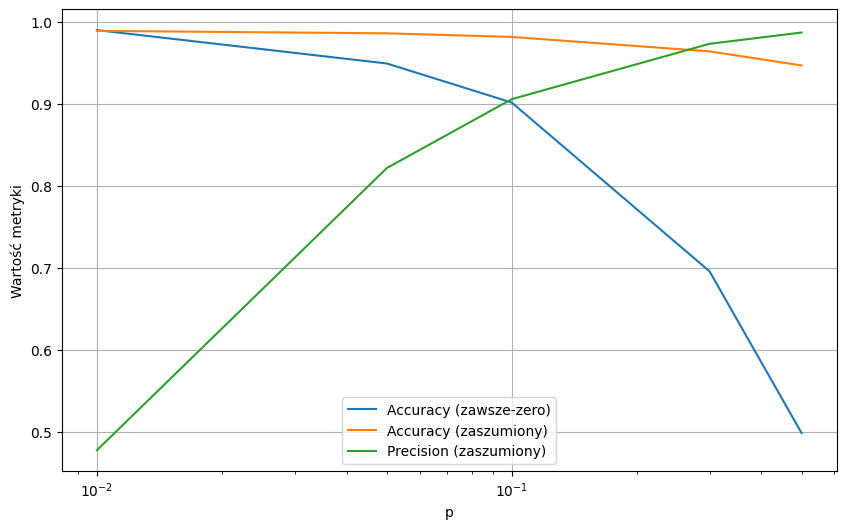

In [301]:
import matplotlib.pyplot as plt

df_zero = df[df["model"] == "zawsze-zero"].sort_values("p")
df_noisy = df[df["model"] == "zaszumiony"].sort_values("p")

plt.figure(figsize=(10, 6))

plt.plot(df_zero["p"], df_zero["accuracy"], label="Accuracy (zawsze-zero)")
plt.plot(df_noisy["p"], df_noisy["accuracy"], label="Accuracy (zaszumiony)")
plt.plot(df_noisy["p"], df_noisy["precision"], label="Precision (zaszumiony)")

plt.xscale("log")

plt.xlabel("p")
plt.ylabel("Wartość metryki")
plt.legend()
plt.grid()
plt.show()

Zmiana na pomyłki w 10% pozytywnych i 1% negatywnych odpowiedzi spowodowało zmiany w accuracy i precision. Nastąpił wzrost accuracy,  a w precision następuje duży wzrost przy małych wartościach p.


